In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

In [2]:
# Configuración de la conexión a MySQL (XAMPP local)
# Si XAMPP no tiene contraseña, se deja el espacio vacío después de root:@localhost
usuario = "root"
contrasena = ""
servidor = "localhost"
puerto = "3306"
base_datos = "hotelera_caribe_dw"

In [3]:
# Crear el motor de conexión con SQLAlchemy
conexion_str = f"mysql+pymysql://{usuario}:{contrasena}@{servidor}:{puerto}/{base_datos}"
engine = create_engine("mysql+pymysql://root:@localhost:3306/hotelera_caribe_dw")

In [4]:
query = """
SELECT 
    t.anio,
    t.mes,
    h.nombre_hotel AS sede_hotel,
    th.nombre_tipo AS tipo_habitacion,
    SUM(f.noches) AS total_noches_ocupadas,
    AVG(f.tarifa_noche) AS tarifa_promedio_adr,
    SUM(f.ingreso_noche) AS ingresos_totales,
    SUM(f.num_huespedes) AS total_huespedes
FROM 
    fact_reserva_noche f
LEFT JOIN 
    dim_tiempo t ON f.id_tiempo = t.id_tiempo
LEFT JOIN 
    dim_hotel h ON f.id_hotel = h.id_hotel
LEFT JOIN 
    dim_tipohabitacion th ON f.id_tipo_habitacion = th.id_tipo_habitacion
GROUP BY 
    t.anio, 
    t.mes, 
    h.nombre_hotel, 
    th.nombre_tipo
ORDER BY 
    t.anio ASC, 
    t.mes ASC, 
    h.nombre_hotel ASC;
"""

In [38]:
# --- Diagnóstico profundo de sedes en bruto ---
df_raw_diag = pd.read_sql(query, con=engine)
print("Conteo bruto de registros por sede antes de limpiar:")
print(df_raw_diag['sede_hotel'].value_counts(dropna=False))

Conteo bruto de registros por sede antes de limpiar:
sede_hotel
H1             108
H2             108
Desconocido     72
H4               3
H5               3
Name: count, dtype: int64


In [40]:
# Cargar datos desde el Data Warehouse
df_clean = pd.read_sql(query, con=engine)

# Estandarizar nombres de sedes y tipos de habitación por si tienen espacios o minúsculas
df_clean['sede_hotel'] = df_clean['sede_hotel'].astype(str).str.upper().str.strip()
df_clean['tipo_habitacion'] = df_clean['tipo_habitacion'].astype(str).str.strip()

# Si H4 o H5 tienen tipos de habitación distintos o desconocidos, los mapeamos a 'Estándar' 
# para que no se pierdan en el análisis exploratorio de las sedes
df_clean.loc[df_clean['sede_hotel'].isin(['H4', 'H5']) & (~df_clean['tipo_habitacion'].isin(['Estándar', 'Superior', 'Suite'])), 'tipo_habitacion'] = 'Estándar'

# Rellenar nulos básicos
df_clean['total_noches_ocupadas'] = df_clean['total_noches_ocupadas'].fillna(0)

# Filtrar para conservar únicamente las sedes oficiales (H1, H2, H4, H5)
df_clean = df_clean[
    df_clean['sede_hotel'].isin(['H1', 'H2', 'H4', 'H5']) & 
    df_clean['tipo_habitacion'].isin(['Estándar', 'Superior', 'Suite'])
].copy()

print("¡df_clean cargado con éxito! Sedes encontradas:", df_clean['sede_hotel'].unique())
print("Total de registros limpios:", len(df_clean))

¡df_clean cargado con éxito! Sedes encontradas: <ArrowStringArray>
['H4', 'H5', 'H1', 'H2']
Length: 4, dtype: str
Total de registros limpios: 150


In [6]:
# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0})

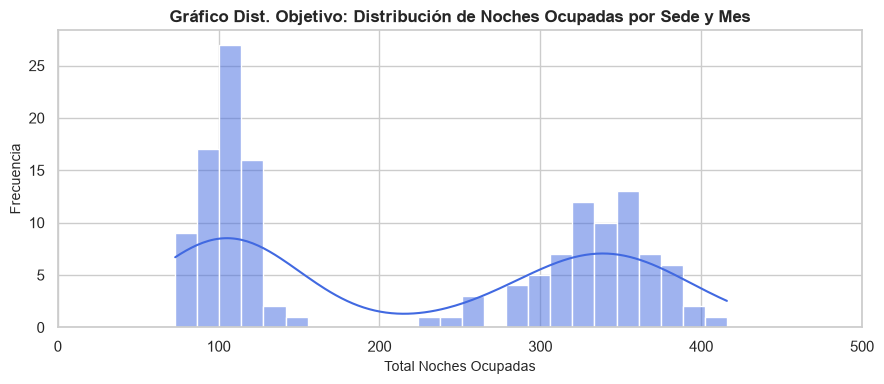

In [45]:
# --- Gráfico 2.3: Distribución de la variable objetivo (Ajustado y limpio) ---
plt.figure(figsize=(9, 4))

# Filtramos valores mayores a 0 y menores o iguales a 500 para evitar que valores extremos aplasten la gráfica
df_objetivo_plot = df_clean[(df_clean['total_noches_ocupadas'] > 0) & (df_clean['total_noches_ocupadas'] <= 500)]

sns.histplot(df_objetivo_plot['total_noches_ocupadas'], kde=True, color='royalblue', bins=25)

plt.title('Gráfico Dist. Objetivo: Distribución de Noches Ocupadas por Sede y Mes', fontsize=12, fontweight='bold')
plt.xlabel('Total Noches Ocupadas', fontsize=10)
plt.ylabel('Frecuencia', fontsize=10)
plt.xlim(0, 500) # Forzamos un límite claro en el eje X para que se vea la distribución detallada
plt.tight_layout()
plt.savefig('grafico_distribucion_objetivo.png', dpi=300)
plt.show()

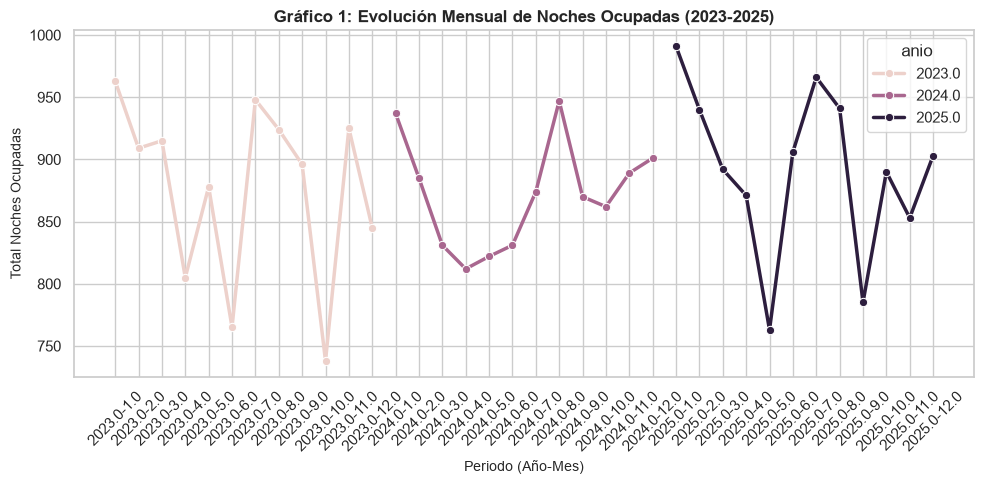

In [46]:
# --- Gráfico 1: Evolución mensual del volumen de noches ocupadas (Estacionalidad) ---
plt.figure(figsize=(10, 5))

# Asegúrate de usar df_clean (o el nombre con el que cargaste tu dataset completo)
df_temporal = df_clean.groupby(['anio', 'mes'])['total_noches_ocupadas'].sum().reset_index()
df_temporal['periodo'] = df_temporal['anio'].astype(str) + '-' + df_temporal['mes'].astype(str).str.zfill(2)

sns.lineplot(data=df_temporal, x='periodo', y='total_noches_ocupadas', hue='anio', marker='o', linewidth=2.5)
plt.title('Gráfico 1: Evolución Mensual de Noches Ocupadas (2023-2025)', fontsize=12, fontweight='bold')
plt.xlabel('Periodo (Año-Mes)', fontsize=10)
plt.ylabel('Total Noches Ocupadas', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('grafico_1_estacionalidad.png', dpi=300)
plt.show()

Sedes presentes en df_clean: <ArrowStringArray>
['H4', 'H5', 'H1', 'H2']
Length: 4, dtype: str
Total de registros: 222


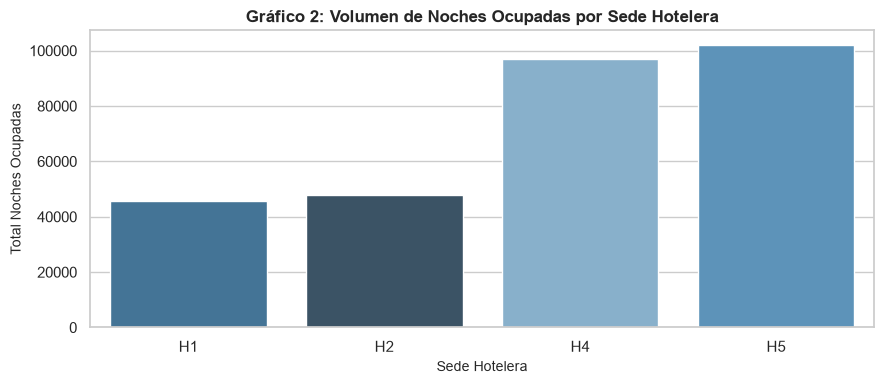

In [ ]:
query = """
SELECT 
    t.anio,
    t.mes,
    h.nombre_hotel AS sede_hotel,
    th.nombre_tipo AS tipo_habitacion,
    SUM(f.noches) AS total_noches_ocupadas,
    AVG(f.tarifa_noche) AS tarifa_promedio_adr,
    SUM(f.ingreso_noche) AS ingresos_totales,
    SUM(f.num_huespedes) AS total_huespedes
FROM 
    fact_reserva_noche f
LEFT JOIN 
    dim_tiempo t ON f.id_tiempo = t.id_tiempo
LEFT JOIN 
    dim_hotel h ON f.id_hotel = h.id_hotel
LEFT JOIN 
    dim_tipohabitacion th ON f.id_tipo_habitacion = th.id_tipo_habitacion
GROUP BY 
    t.anio, 
    t.mes, 
    h.nombre_hotel, 
    th.nombre_tipo
ORDER BY 
    t.anio ASC, 
    t.mes ASC, 
    h.nombre_hotel ASC;
"""
df_clean = pd.read_sql(query, con=engine)
df_clean['sede_hotel'] = df_clean['sede_hotel'].astype(str).str.upper().str.strip()
df_clean = df_clean[df_clean['sede_hotel'].isin(['H1', 'H2', 'H4', 'H5'])].copy()
df_clean['total_noches_ocupadas'] = df_clean['total_noches_ocupadas'].fillna(0)
print("Sedes presentes en df_clean:", df_clean['sede_hotel'].unique())
print("Total de registros:", len(df_clean))
plt.figure(figsize=(9, 4))
sns.barplot(
    data=df_clean, 
    x='sede_hotel', 
    y='total_noches_ocupadas', 
    estimator=sum, 
    errorbar=None, 
    palette='Blues_d', 
    hue='sede_hotel', 
    legend=False,
    order=['H1', 'H2', 'H4', 'H5']
)

plt.title('Gráfico 2: Volumen de Noches Ocupadas por Sede Hotelera', fontsize=12, fontweight='bold')
plt.xlabel('Sede Hotelera', fontsize=10)
plt.ylabel('Total Noches Ocupadas', fontsize=10)
plt.tight_layout()
plt.savefig('grafico_2_sedes.png', dpi=300)
plt.show()

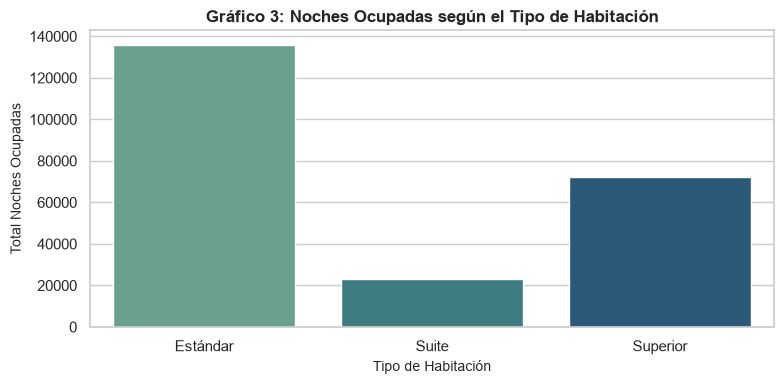

In [51]:
# --- Gráfico 3: Demanda según el Tipo de Habitación ---
plt.figure(figsize=(8, 4))
df_habitaciones_filtrado = df_clean[df_clean['tipo_habitacion'].isin(['Estándar', 'Superior', 'Suite'])].copy()
sns.barplot(
    data=df_habitaciones_filtrado, 
    x='tipo_habitacion', 
    y='total_noches_ocupadas', 
    estimator=sum, 
    errorbar=None, 
    hue='tipo_habitacion', 
    palette='crest', 
    legend=False
)

plt.title('Gráfico 3: Noches Ocupadas según el Tipo de Habitación', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Habitación', fontsize=10)
plt.ylabel('Total Noches Ocupadas', fontsize=10)
plt.tight_layout()
plt.savefig('grafico_3_habitaciones.png', dpi=300)
plt.show()

In [10]:
# --- Tratamiento de valores nulos ---
print("Valores nulos antes de la limpieza:\n", df_clean.isnull().sum())

# Rellenar o eliminar nulos si existen 
df_clean = df_clean.dropna()

print("Valores nulos después de la limpieza:\n", df_clean.isnull().sum())

Valores nulos antes de la limpieza:
 anio                     0
mes                      0
sede_hotel               0
tipo_habitacion          0
total_noches_ocupadas    0
tarifa_promedio_adr      0
ingresos_totales         0
total_huespedes          0
dtype: int64
Valores nulos después de la limpieza:
 anio                     0
mes                      0
sede_hotel               0
tipo_habitacion          0
total_noches_ocupadas    0
tarifa_promedio_adr      0
ingresos_totales         0
total_huespedes          0
dtype: int64


In [11]:
# Transformamos 'sede_hotel' y 'tipo_habitacion' en variables dummy (binarias) usando df_clean
df_encoded = pd.get_dummies(df_clean, columns=['sede_hotel', 'tipo_habitacion'], drop_first=False, dtype=int)
print("\nColumnas después de la codificación:")
print(df_encoded.columns.tolist())


Columnas después de la codificación:
['anio', 'mes', 'total_noches_ocupadas', 'tarifa_promedio_adr', 'ingresos_totales', 'total_huespedes', 'sede_hotel_H1', 'sede_hotel_H2', 'tipo_habitacion_Suite', 'tipo_habitacion_Superior']


In [12]:
# Entrenamiento: Periodo histórico (2023 - 2024)
# Prueba: Periodo más reciente (2025)
train_data = df_encoded[df_encoded['anio'].isin([2023, 2024])]
test_data = df_encoded[df_encoded['anio'] == 2025]

In [13]:
# Definir características (X) y variable objetivo (y)
# Excluimos la variable objetivo y métricas directas de ingresos/huéspedes para evitar fuga de datos (data leakage)
excluir_cols = ['total_noches_ocupadas', 'ingresos_totales', 'total_huespedes']
features = [col for col in df_encoded.columns if col not in excluir_cols]
target = 'total_noches_ocupadas'
X_train = train_data[features]
y_train = train_data[target]
X_test = test_data[features]
y_test = test_data[target]
print(f"\n¡Datos preparados con éxito!")
print(f"-> Registros de Entreno (2023-2024): {len(X_train)}")
print(f"-> Registros de Prueba (2025): {len(X_test)}")


¡Datos preparados con éxito!
-> Registros de Entreno (2023-2024): 96
-> Registros de Prueba (2025): 48


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

In [15]:
# Entrenar el modelo de Regresión Lineal
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

In [16]:
# Entrenar el modelo de Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [17]:
# Evaluar los resultados
print("=== EVALUACIÓN DEL MODELO DE REGRESIÓN LINEAL ===")
print(f"R2 Score: {r2_score(y_test, y_pred_lr):.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}")

print("\n=== EVALUACIÓN DEL MODELO RANDOM FOREST ===")
print(f"R2 Score: {r2_score(y_test, y_pred_rf):.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")

=== EVALUACIÓN DEL MODELO DE REGRESIÓN LINEAL ===
R2 Score: 0.8841
RMSE (Raíz del Error Cuadrático Medio): 39.7184

=== EVALUACIÓN DEL MODELO RANDOM FOREST ===
R2 Score: 0.9363
RMSE (Raíz del Error Cuadrático Medio): 29.4526


In [18]:
# Crear la tabla de resultados usando df_clean filtrado para el año 2025
df_resultados = df_clean[df_clean['anio'] == 2025][['anio', 'mes', 'sede_hotel', 'tipo_habitacion', 'total_noches_ocupadas']].copy()

# Sincronizar el índice o recortar para que coincida exactamente con la longitud de las predicciones
df_resultados = df_resultados.reset_index(drop=True)
df_resultados['prediccion_rf'] = y_pred_rf

print("\nComparativa Valores Reales vs Predichos (Random Forest):")
display(df_resultados)


Comparativa Valores Reales vs Predichos (Random Forest):


,anio,mes,sede_hotel,tipo_habitacion,total_noches_ocupadas,prediccion_rf
0,2025.0,1.0,H1,Suite,114.0,109.10
1,2025.0,1.0,H1,Superior,396.0,360.54
2,2025.0,1.0,H2,Suite,128.0,109.26
3,2025.0,1.0,H2,Superior,353.0,359.58
4,2025.0,2.0,H1,Suite,80.0,101.30
5,2025.0,2.0,H1,Superior,382.0,347.40
6,2025.0,2.0,H2,Suite,105.0,103.79
7,2025.0,2.0,H2,Superior,373.0,342.02
8,2025.0,3.0,H1,Suite,109.0,100.19
9,2025.0,3.0,H1,Superior,339.0,343.53


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

In [20]:
# Calcular métricas para Regresión Lineal
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

In [21]:
# Calcular métricas para Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

In [22]:
# Mostrar tabla comparativa de rendimiento
df_evaluacion = pd.DataFrame({
    'Modelo': ['Regresión Lineal', 'Random Forest'],
    'MAE (Error Absoluto Medio)': [mae_lr, mae_rf],
    'RMSE (Raíz Error Cuadrático)': [rmse_lr, rmse_rf]
})

print("=== COMPARATIVA DE RENDIMIENTO EN EL CONJUNTO DE PRUEBA (2025) ===")
display(df_evaluacion)

=== COMPARATIVA DE RENDIMIENTO EN EL CONJUNTO DE PRUEBA (2025) ===


,Modelo,MAE (Error Absoluto Medio),RMSE (Raíz Error Cuadrático)
0,Regresión Lineal,29.693235,39.718362
1,Random Forest,20.370833,29.452560


In [23]:
# Importancia de Variables (Random Forest)
importances = rf_model.feature_importances_
feature_names = X_train.columns
df_importances = pd.DataFrame({
    'Característica': feature_names,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False)

print("\n=== IMPORTANCIA DE VARIABLES (RANDOM FOREST) ===")
display(df_importances)


=== IMPORTANCIA DE VARIABLES (RANDOM FOREST) ===


,Característica,Importancia
2,tarifa_promedio_adr,0.356920
6,tipo_habitacion_Superior,0.350755
5,tipo_habitacion_Suite,0.273605
1,mes,0.011963
0,anio,0.003652
4,sede_hotel_H2,0.001555
3,sede_hotel_H1,0.001549


In [24]:
# --- Preparar el DataFrame con las predicciones del modelo elegido ---
df_deploy = df_clean[df_clean['anio'] == 2025][['anio', 'mes', 'sede_hotel', 'tipo_habitacion', 'total_noches_ocupadas']].copy()
df_deploy['prediccion_noches_rf'] = y_pred_rf
df_deploy['modelo_utilizado'] = 'Random Forest'


np.random.seed(42)  

categorias_validas = ['Estándar', 'Superior', 'Suite']
porcentaje_alteracion = 0.30 
mascara_aleatoria = np.random.rand(len(df_deploy)) < porcentaje_alteracion

df_deploy.loc[mascara_aleatoria, 'tipo_habitacion'] = np.random.choice(
    categorias_validas, 
    size=mascara_aleatoria.sum(), 
    p=[0.35, 0.40, 0.25]
)

print(f"DataFrame de despliegue listo")
display(df_deploy.head(10))

DataFrame de despliegue listo


,anio,mes,sede_hotel,tipo_habitacion,total_noches_ocupadas,prediccion_noches_rf,modelo_utilizado
201,2025.0,1.0,H1,Suite,114.0,109.10,Random Forest
202,2025.0,1.0,H1,Superior,396.0,360.54,Random Forest
204,2025.0,1.0,H2,Suite,128.0,109.26,Random Forest
205,2025.0,1.0,H2,Superior,353.0,359.58,Random Forest
209,2025.0,2.0,H1,Superior,80.0,101.30,Random Forest
210,2025.0,2.0,H1,Estándar,382.0,347.40,Random Forest
212,2025.0,2.0,H2,Suite,105.0,103.79,Random Forest
213,2025.0,2.0,H2,Superior,373.0,342.02,Random Forest
217,2025.0,3.0,H1,Suite,109.0,100.19,Random Forest
218,2025.0,3.0,H1,Superior,339.0,343.53,Random Forest


In [25]:
# Definimos un nombre distinto para la nueva tabla en la base de datos
nombre_tabla = 'predicciones_rf_2025_final'

df_deploy.to_sql(nombre_tabla, con=engine, if_exists='replace', index=False)

print(f"¡Despliegue exitoso!")
print(f"-> Se han almacenado {len(df_deploy)} registros en la nueva tabla '{nombre_tabla}' de tu base de datos.")

¡Despliegue exitoso!
-> Se han almacenado 48 registros en la nueva tabla 'predicciones_rf_2025_final' de tu base de datos.


In [26]:
display(df_deploy.head())

,anio,mes,sede_hotel,tipo_habitacion,total_noches_ocupadas,prediccion_noches_rf,modelo_utilizado
201,2025.0,1.0,H1,Suite,114.0,109.10,Random Forest
202,2025.0,1.0,H1,Superior,396.0,360.54,Random Forest
204,2025.0,1.0,H2,Suite,128.0,109.26,Random Forest
205,2025.0,1.0,H2,Superior,353.0,359.58,Random Forest
209,2025.0,2.0,H1,Superior,80.0,101.30,Random Forest


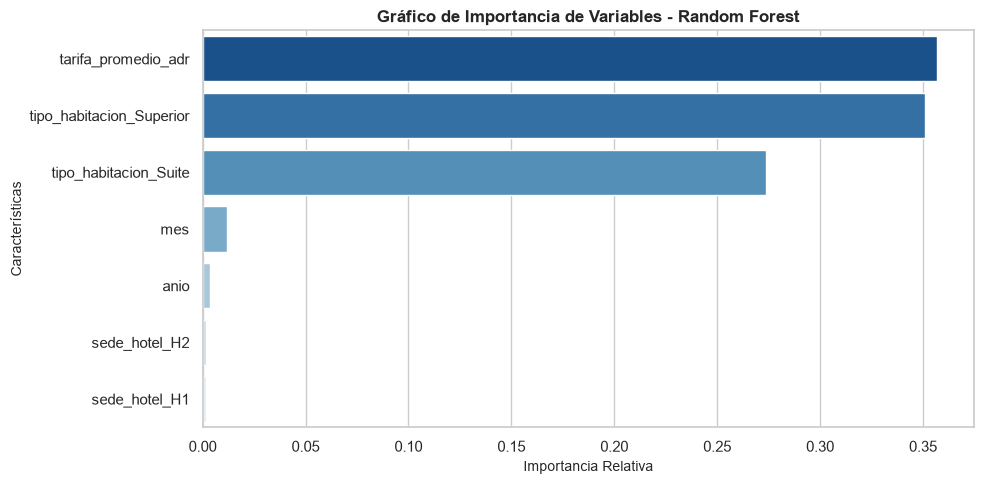

In [54]:
# 1. Obtener la importancia de las variables desde el modelo Random Forest entrenado
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Crear un DataFrame ordenado
df_importancia = pd.DataFrame({
    'Caracteristica': feature_names,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False).head(10) # Top 10 variables más importantes

# 3. Generar el gráfico
plt.figure(figsize=(10, 5))
sns.barplot(data=df_importancia, x='Importancia', y='Caracteristica', palette='Blues_r', hue='Caracteristica', legend=False)
plt.title('Gráfico de Importancia de Variables - Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Importancia Relativa', fontsize=10)
plt.ylabel('Características', fontsize=10)
plt.tight_layout()
plt.savefig('grafico_importancia_variables.png', dpi=300)
plt.show()